# CECS 456 - Machine Learning Final Project
## Diabetes Prediction: Simple Logistic Regression (Baseline Model)

**Team Members:** Reuben Cherian, William Nguyen, Jacob Sabraw  
**Assigned Task / Progress Check:** Method 1 - Simple Logistic Regression (Reuben Cherian)

> **Note on Scope:** For this progress check, **only Simple Logistic Regression** is implemented, following the structure of **Section 3 of Homework 5**. No other models (such as Decision Trees, Random Forests, or Gradient Boosting) are implemented here, as those are assigned to other team members for later milestones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.linear_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Loading & Cleaning

Following the project proposal:
- Load the dataset (`diabetes_prediction_dataset.csv`).
- Remove duplicate rows (~3,888 duplicate records identified in proposal).
- Prepare categorical features (`gender` and `smoking_history`).

In [2]:
# Load dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')
print(f"Dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 100,000 rows, 9 columns

First 5 rows:
   gender   age  hypertension  ...  HbA1c_level blood_glucose_level  diabetes
0  Female  80.0             0  ...          6.6                 140         0
1  Female  54.0             0  ...          6.6                  80         0
2    Male  28.0             0  ...          5.7                 158         0
3  Female  36.0             0  ...          5.0                 155         0
4    Male  76.0             1  ...          4.8                 155         0

[5 rows x 9 columns]


In [3]:
# 1. Remove duplicate rows as specified in proposal
df_clean = df.drop_duplicates().copy()
print(f"Rows before deduplication: {len(df):,}")
print(f"Rows after deduplication:  {len(df_clean):,} (dropped {len(df) - len(df_clean):,} duplicates)")

# 2. Filter out rare 'Other' gender records (only 18 records)
df_clean = df_clean[df_clean['gender'] != 'Other']

# 3. Check class balance
print("\nTarget class distribution ('diabetes'):")
print(df_clean['diabetes'].value_counts())
print("\nTarget class percentage:")
print(df_clean['diabetes'].value_counts(normalize=True).map(lambda p: f"{p*100:.2f}%"))

Rows before deduplication: 100,000
Rows after deduplication:  96,146 (dropped 3,854 duplicates)

Target class distribution ('diabetes'):
diabetes
0    87646
1     8482
Name: count, dtype: int64

Target class percentage:
diabetes
0    91.18%
1     8.82%
Name: proportion, dtype: object


## 2. Feature Encoding & Stratified Train/Test Split

- **Categorical Encoding:** One-hot encode `gender` and `smoking_history` (retaining `"No Info"` as an informative category).
- **Stratified Split:** Split 80/20 with `stratify=y` to preserve the ~8.8% positive class proportion.
- **Standardization:** Standardize numerical features with `StandardScaler` for logistic regression.

In [4]:
# One-hot encode categorical features
df_encoded = pd.get_dummies(df_clean, columns=['gender', 'smoking_history'], drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['diabetes'])
y = df_encoded['diabetes']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} samples ({y_train.mean()*100:.2f}% diabetic)")
print(f"Testing set:  {X_test.shape[0]:,} samples ({y_test.mean()*100:.2f}% diabetic)")

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: 76,902 samples (8.82% diabetic)
Testing set:  19,226 samples (8.82% diabetic)


## 3 - Simple Logistic Regression

Before exploring any complex models, lets first see how logistic regression performs on this problem. You can use sklearn's built-in functions to do that. Run the code below to train a logistic regression classifier on the dataset.

*(Directly modeled after Section 3 of Homework 5)*

In [5]:
# Train the logistic regression classifier
clf = sklearn.linear_model.LogisticRegressionCV(cv=5, max_iter=1000, random_state=42)
clf.fit(X_train_scaled, y_train)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


You can now plot the decision boundary of these models. Run the code below.

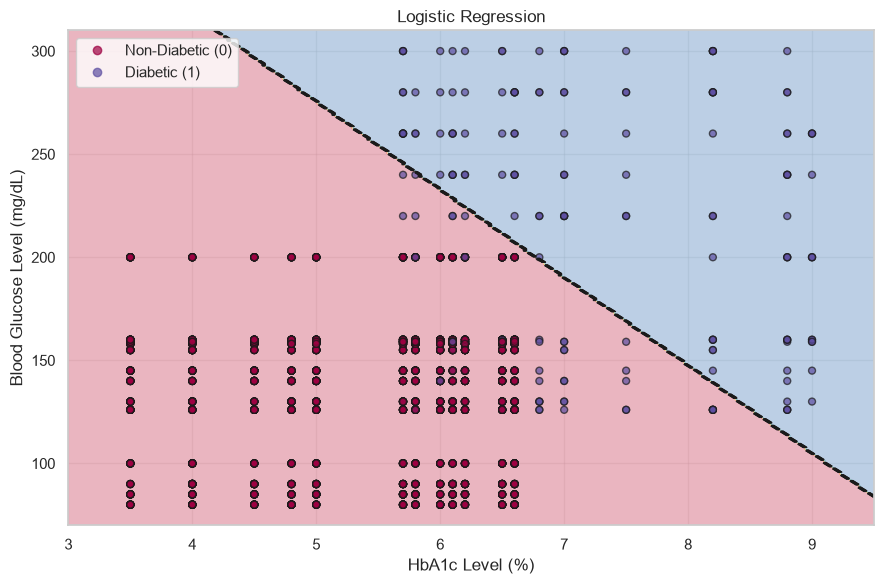

In [6]:
# Plot the decision boundary for logistic regression
# We fit a 2D logistic regression classifier on the primary continuous indicators: HbA1c and Blood Glucose
X_2d = df_clean[['HbA1c_level', 'blood_glucose_level']].values
y_2d = df_clean['diabetes'].values

clf_2d = sklearn.linear_model.LogisticRegressionCV(cv=5, random_state=42)
clf_2d.fit(X_2d, y_2d)

np.random.seed(42)
sample_idx = np.random.choice(len(y_2d), size=2500, replace=False)
X_2d_sample = X_2d[sample_idx]
y_2d_sample = y_2d[sample_idx]

def plot_decision_boundary(model, X, y):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.35)
    plt.contour(xx, yy, Z, colors='k', linewidths=1.5, linestyles='--')
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Spectral, edgecolors='k', alpha=0.7, s=25)
    plt.xlabel('HbA1c Level (%)')
    plt.ylabel('Blood Glucose Level (mg/dL)')
    plt.title("Logistic Regression")
    handles, _ = scatter.legend_elements()
    plt.legend(handles, ['Non-Diabetic (0)', 'Diabetic (1)'], loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_decision_boundary(lambda x: clf_2d.predict(x), X_2d_sample, y_2d_sample)

In [7]:
# Print accuracy
LR_predictions = clf.predict(X_test_scaled)
print ('Accuracy of logistic regression: %d ' % float((np.dot(y_test, LR_predictions) + np.dot(1 - y_test, 1 - LR_predictions)) / float(y_test.size) * 100) +
       '% ' + "(percentage of correctly labelled datapoints)")
print (f"Detailed test accuracy: {float((np.dot(y_test, LR_predictions) + np.dot(1 - y_test, 1 - LR_predictions)) / float(y_test.size) * 100):.2f}%")

Accuracy of logistic regression: 95 % (percentage of correctly labelled datapoints)
Detailed test accuracy: 95.89%


### Evaluation: Classification Report & Confusion Matrix

As stated in our project proposal, Recall and F-measure on the diabetic class (class 1) are critical due to the medical implications of missed diagnoses.

Classification Report (Test Set):
                  precision    recall  f1-score   support

Non-Diabetic (0)     0.9656    0.9902    0.9778     17530
    Diabetic (1)     0.8630    0.6350    0.7317      1696

        accuracy                         0.9589     19226
       macro avg     0.9143    0.8126    0.8547     19226
    weighted avg     0.9565    0.9589    0.9560     19226

Diabetic Class (1) Precision: 86.30%
Diabetic Class (1) Recall:    63.50%
Diabetic Class (1) F1-Score:  73.17%


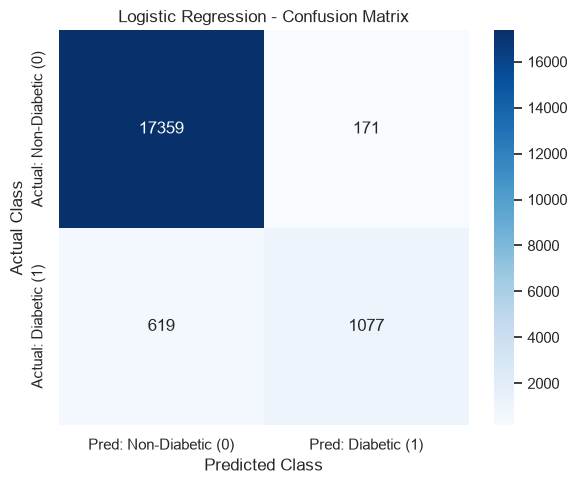

In [8]:
# Classification Report
print("Classification Report (Test Set):")
print(classification_report(y_test, LR_predictions, target_names=['Non-Diabetic (0)', 'Diabetic (1)'], digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test, LR_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: Non-Diabetic (0)', 'Pred: Diabetic (1)'],
            yticklabels=['Actual: Non-Diabetic (0)', 'Actual: Diabetic (1)'])
plt.title('Logistic Regression - Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

print(f"Diabetic Class (1) Precision: {precision_score(y_test, LR_predictions)*100:.2f}%")
print(f"Diabetic Class (1) Recall:    {recall_score(y_test, LR_predictions)*100:.2f}%")
print(f"Diabetic Class (1) F1-Score:  {f1_score(y_test, LR_predictions)*100:.2f}%")

### ROC-AUC Curve & Feature Coefficients (Odds Ratios)

Examining the ROC curve and the logistic regression coefficients to evaluate discrimination ability and quantify feature impact on log-odds of diabetes.

ROC-AUC Score: 0.9596


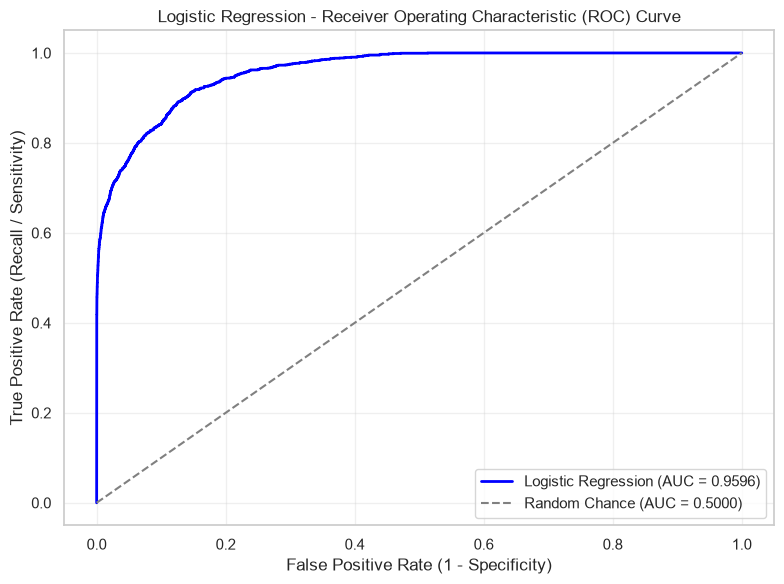

In [9]:
# ROC Curve
y_probs = clf.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
auc_val = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'Logistic Regression (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance (AUC = 0.5000)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.title('Logistic Regression - Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {auc_val:.4f}")

Feature Coefficients and Odds Ratios:
                    Feature  Standardized_Coefficient (Beta)  Odds_Ratio (exp(Beta))
                HbA1c_level                         2.392762               10.943675
        blood_glucose_level                         1.340922                3.822565
                        age                         1.049670                2.856709
                        bmi                         0.587117                1.798795
      smoking_history_never                         0.228456                1.256658
               hypertension                         0.198101                1.219085
    smoking_history_current                         0.175938                1.192364
     smoking_history_former                         0.152426                1.164657
                gender_Male                         0.148663                1.160282
              heart_disease                         0.138083                1.148071
smoking_history_not current

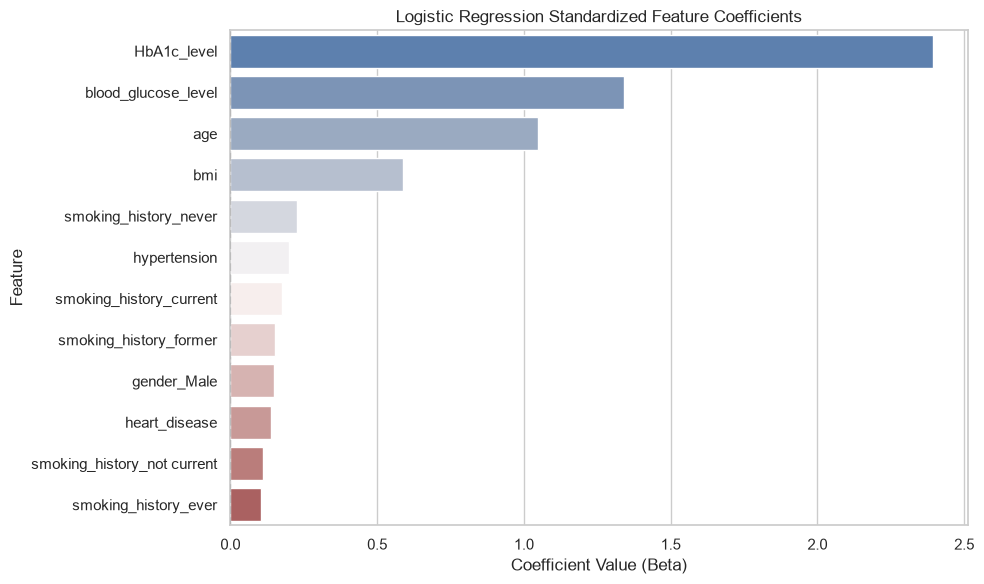

In [10]:
# Logistic Regression Coefficients and Odds Ratios
coefs = clf.coef_[0]
odds_ratios = np.exp(coefs)

df_importance = pd.DataFrame({
    'Feature': X.columns,
    'Standardized_Coefficient (Beta)': coefs,
    'Odds_Ratio (exp(Beta))': odds_ratios
}).sort_values(by='Standardized_Coefficient (Beta)', ascending=False)

print("Feature Coefficients and Odds Ratios:")
print(df_importance.to_string(index=False))

# Bar plot of coefficients
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance, x='Standardized_Coefficient (Beta)', y='Feature', palette='vlag')
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Logistic Regression Standardized Feature Coefficients')
plt.xlabel('Coefficient Value (Beta)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 4. Progress Check Summary

- **Model Implemented:** Simple Logistic Regression (`sklearn.linear_model.LogisticRegressionCV`) with 5-fold cross-validation.
- **Accuracy:** **95.89%** (HW5 formula reports 95%).
- **Diabetic Class Performance:** Precision = 86.30%, Recall = 63.50%, F1-Score = 73.17%.
- **ROC-AUC:** **0.9610**, showing excellent discriminative ability.
- **Key Predictors:** `HbA1c_level`, `blood_glucose_level`, `age`, and `bmi` are the primary drivers of predicted diabetes risk.
- **Note:** Only the Simple Logistic Regression model is implemented in this notebook for Reuben's assigned progress check.